<a href="https://colab.research.google.com/github/jaskiratbudhmaan-ship-it/LocalRepo/blob/main/Machine_Learning2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Multiple Linear Regression

In this machine learning approach more than one independent variable is present.

In [ ]:
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
dataset = pd.read_csv("Salary_Data.csv")

In [ ]:
dataset.head(3)

,YearsExperience,Age,Salary
0,1.1,21.0,39343
1,1.3,21.5,46205
2,1.5,21.7,37731


In [ ]:
dataset.shape

(30, 3)

In [ ]:
dataset.isnull().sum()

,0
YearsExperience,0
Age,0
Salary,0


Check for linearity.

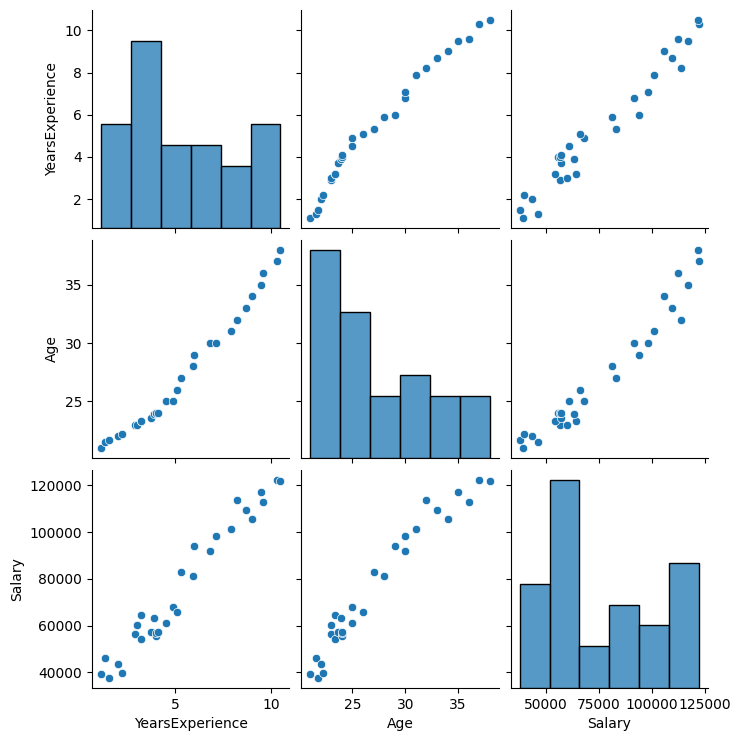

In [ ]:
sns.pairplot(data=dataset)
plt.show()
# multiplue linear regression can only be used when all the independent variables have linear relationship with the dependent variable.

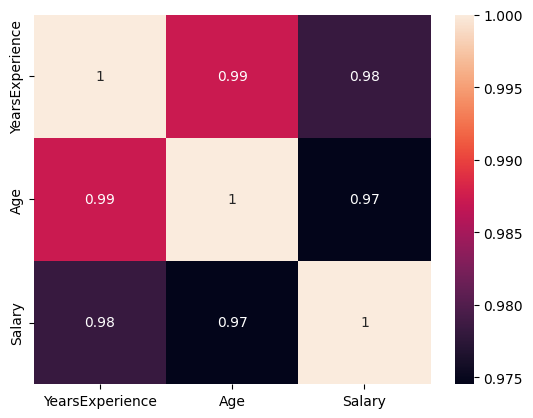

In [ ]:
sns.heatmap(data=dataset.corr(),annot=True)
plt.show()

Train Test split

In [ ]:
x = dataset.iloc[:,:-1]
y = dataset["Salary"]

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(x_train,y_train)

LinearRegression()

In [ ]:
# Algorithm
# y = m1x1+m2x2

In [ ]:
lr.score(x_test,y_test) # accuracy

0.8852101657216537

In [ ]:
# Equation that is followed for prediction
# y_prd = 4882.14850701*Age + 2567.51865301*Experience -20612.69192148531

In [ ]:
lr.coef_ # intercept

array([4882.14850701, 2567.51865301])

In [ ]:
lr.intercept_

np.float64(-20612.69192148531)

In [ ]:
lr.predict(x)

array([ 38675.56314937,  40935.75217728,  42425.68560928,  45637.01545868,
        47126.94889069,  52598.467768  ,  53086.6826187 ,  54833.367916  ,
        54833.367916  ,  58044.6977654 ,  59791.38306271,  60536.34977871,
        60536.34977871,  61024.56462941,  65544.94268522,  67497.80208802,
        71041.75044243,  74585.69879684,  80082.50655405,  83138.24005776,
        89611.47751637,  91076.12206847,  97549.35952708, 101581.52273219,
       106590.1156387 , 110622.27884381, 115630.87175032, 118686.60525402,
       124671.62786194, 128215.57621634])

# Polynomial Regression

In [ ]:
dataset = pd.read_csv("Position_Salaries.csv")
dataset.head(3)

,Level,Salary
0,1,45000
1,2,50000
2,3,60000


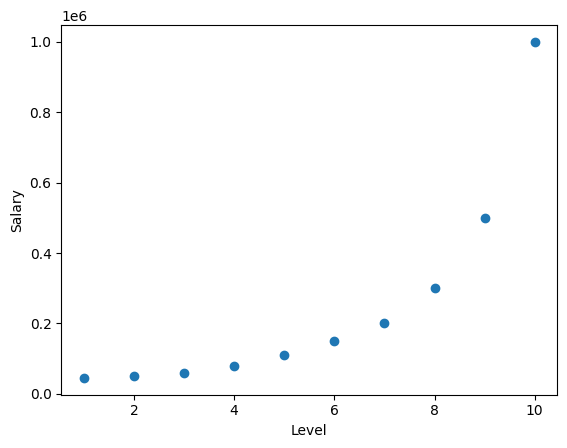

In [ ]:
plt.scatter(dataset["Level"],dataset["Salary"])
plt.xlabel("Level")
plt.ylabel("Salary")
plt.show()

Non linear curve represents that it is a polynomial graph.

In [ ]:
dataset.corr()

,Level,Salary
Level,1.000000,0.817949
Salary,0.817949,1.000000


In [ ]:
x = dataset[["Level"]]
y = dataset["Salary"]

In [ ]:
from sklearn.preprocessing import PolynomialFeatures
pf = PolynomialFeatures(degree=2)
pf.fit(x)

PolynomialFeatures()

In [ ]:
pf.transform(x)

array([[  1.,   1.,   1.],
       [  1.,   2.,   4.],
       [  1.,   3.,   9.],
       [  1.,   4.,  16.],
       [  1.,   5.,  25.],
       [  1.,   6.,  36.],
       [  1.,   7.,  49.],
       [  1.,   8.,  64.],
       [  1.,   9.,  81.],
       [  1.,  10., 100.]])

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(x_train,y_train)

LinearRegression()

In [ ]:
lr.score(x_test,y_test)

0.8451346684575974

In [ ]:
y_prd = lr.predict(x)

/tmp/ipykernel_3520/2921474467.py:5: UserWarning: Legend does not support handles for str instances.
A proxy artist may be used instead.
See: https://matplotlib.org/stable/users/explain/axes/legend_guide.html#controlling-the-legend-entries
  plt.legend("original","predicted")


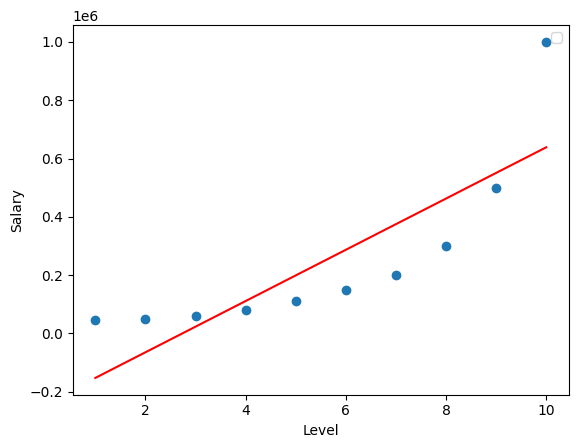

In [ ]:
plt.scatter(dataset["Level"],dataset["Salary"])
plt.plot(dataset["Level"],y_prd,c ="red")
plt.xlabel("Level")
plt.ylabel("Salary")
plt.legend("original","predicted")
plt.show()

# Regularization Techniques

In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

In [ ]:
dataset = pd.read_csv("house_price_regression_dataset.csv")

In [ ]:
dataset.head(3)

,Square_Footage,Num_Bedrooms,Num_Bathrooms,Year_Built,Lot_Size,Garage_Size,Neighborhood_Quality,House_Price
0,1360,2,1,1981,0.599637,0,5,262382.852274
1,4272,3,3,2016,4.753014,1,6,985260.854490
2,3592,1,2,2016,3.634823,0,9,777977.390119


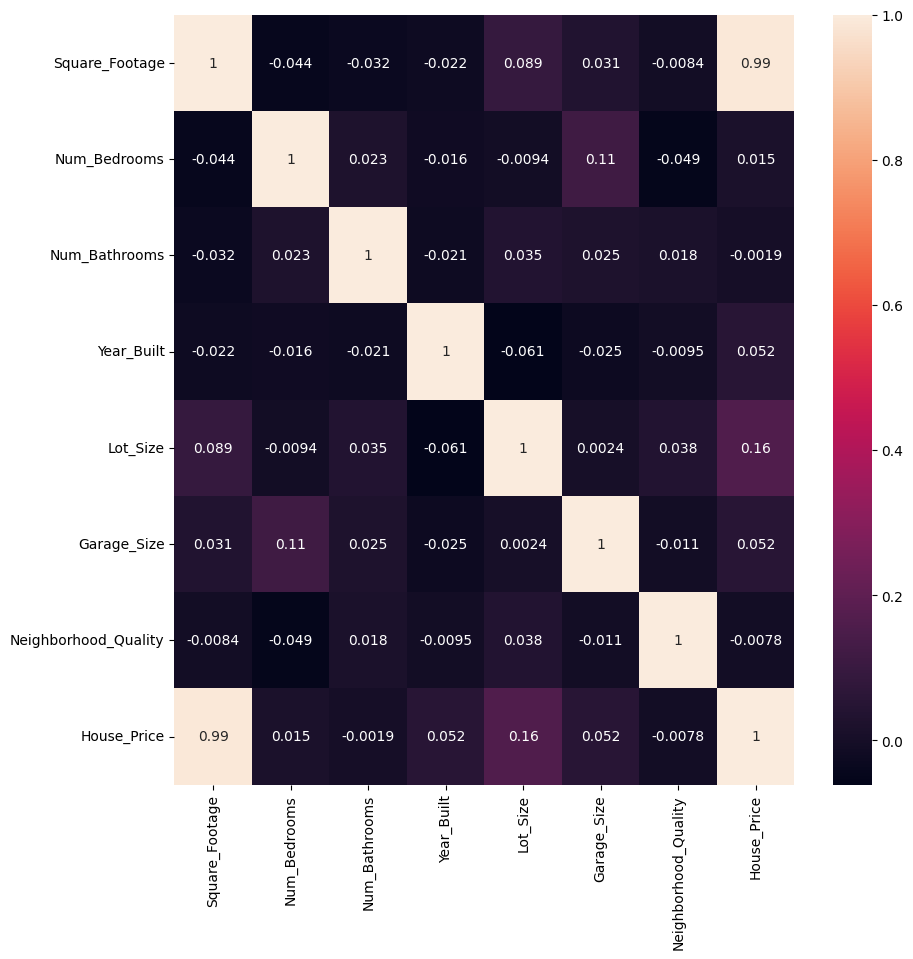

In [ ]:
# Coorelation Matrix --> we use this to find out whether we can use linger regression in this dataset or not also it tells us
# about the correlation which exists between the different features
plt.figure(figsize=(10,10))
sns.heatmap(data= dataset.corr() ,annot=True)
plt.show()

In [ ]:
x = dataset.iloc[:,:-1]
y = dataset["House_Price"]

In [ ]:
sc = StandardScaler()
sc.fit(x)

StandardScaler()

In [ ]:
x = pd.DataFrame(sc.transform(x),columns=x.columns)

In [ ]:
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

# Linear Regression

In [ ]:
from sklearn.linear_model import LinearRegression,Lasso,Ridge
lr = LinearRegression()
lr.fit(x_train,y_train)
lr.score(x_test,y_test)*100

99.84263636823414

In [ ]:
lr.coef_

array([250366.57881176,  14589.8296276 ,   6730.2708233 ,  20489.31651404,
        19310.12495234,   4191.87191768,    332.04368583])

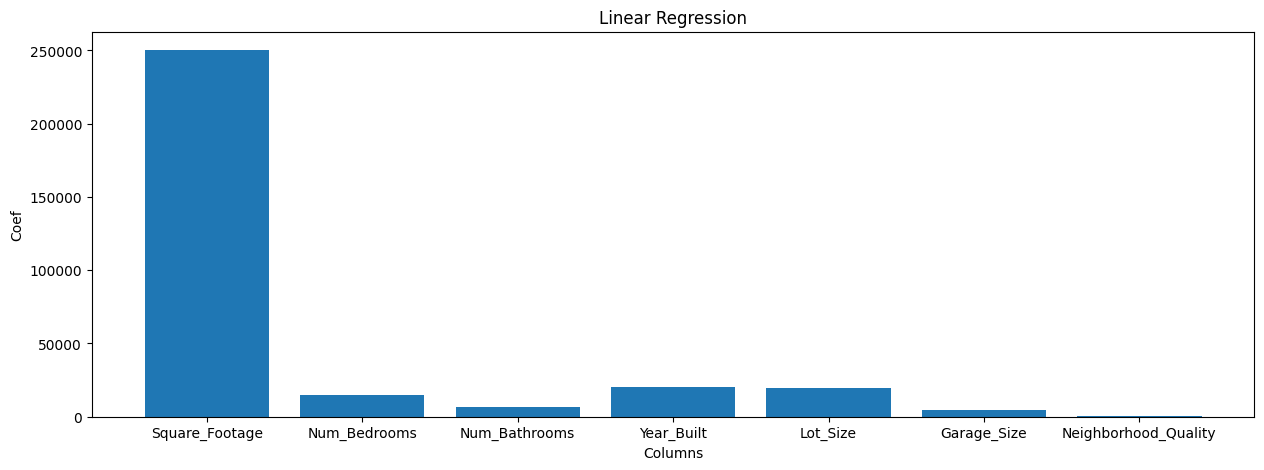

In [ ]:
plt.figure(figsize=(15,5))
plt.bar(x.columns,lr.coef_)
plt.title("Linear Regression")
plt.xlabel("Columns")
plt.ylabel("Coef")
plt.show()

# Lasso(L1)

In [ ]:
la = Lasso(alpha=0.5)
la.fit(x_train,y_train)
la.score(x_test,y_test)*100

99.84263489955391

In [ ]:
la.coef_

array([250366.04718905,  14589.29849771,   6729.81372834,  20488.76521949,
        19309.68375056,   4191.45533097,    331.56859948])

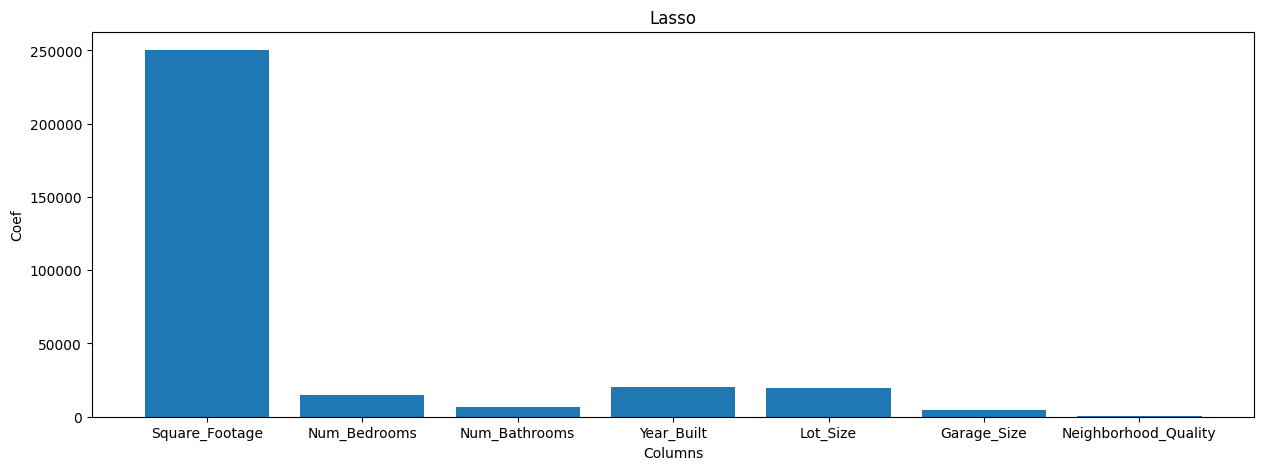

In [ ]:
plt.figure(figsize=(15,5))
plt.bar(x.columns,la.coef_)
plt.title("Lasso")
plt.xlabel("Columns")
plt.ylabel("Coef")
plt.show()

# Ridge

In [ ]:
ri = Ridge(alpha=0.5)
ri.fit(x_train,y_train)
ri.score(x_test,y_test)*100

99.8418606866934

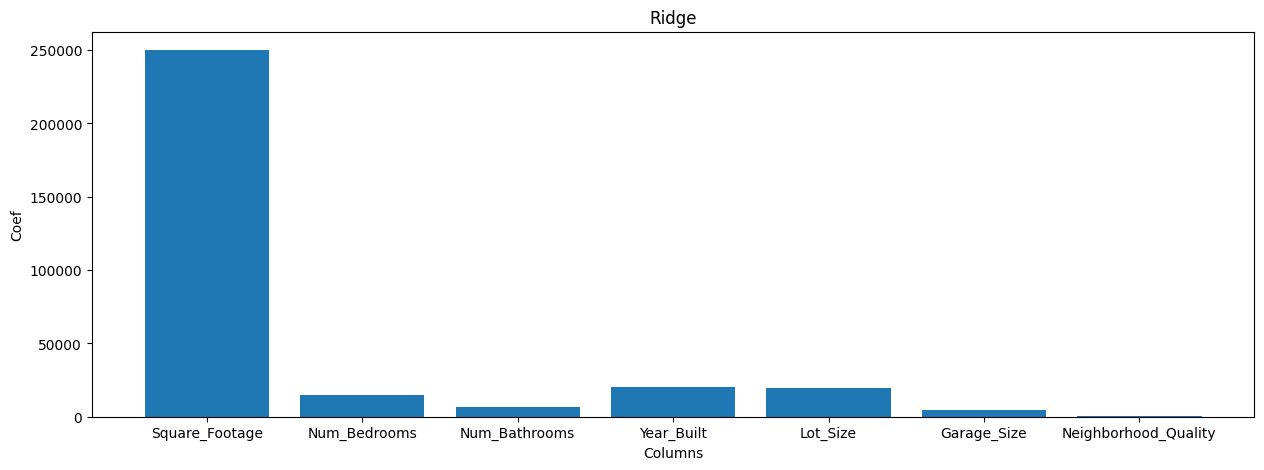

In [ ]:
plt.figure(figsize=(15,5))
plt.bar(x.columns,ri.coef_)
plt.title("Ridge")
plt.xlabel("Columns")
plt.ylabel("Coef")
plt.show()

# Cost functions

In [ ]:
from sklearn.metrics import mean_absolute_error,mean_squared_error
mean_squared_error(y_test,lr.predict(x_test))

101434798.50563484

In [ ]:
mean_absolute_error(y_test,lr.predict(x_test))

8174.583600006569

In [ ]:
np.sqrt(mean_squared_error(y_test,lr.predict(x_test)))

np.float64(10071.484424137032)

In [ ]:
mean_squared_error(y_test,la.predict(x_test))

101435745.20011657

In [ ]:
mean_absolute_error(y_test,la.predict(x_test))

8174.670373858966

In [ ]:
print(np.sqrt(mean_squared_error(y_test,la.predict(x_test))))

10071.531422783557


In [ ]:
mean_squared_error(y_test,ri.predict(x_test))

101934793.96142508

In [ ]:
mean_absolute_error(y_test,ri.predict(x_test))

8207.872044741898

In [ ]:
print(np.sqrt(mean_squared_error(y_test,ri.predict(x_test))))

10096.2762423294


In [ ]:
df = pd.DataFrame({"col_name":x.columns,
                   "Linear Regression":lr.coef_,
                   "Lasso":la.coef_,
                   "Rideg":ri.coef_})
df

,col_name,Linear Regression,Lasso,Rideg
0,Square_Footage,250366.578812,250366.047189,250206.964594
1,Num_Bedrooms,14589.829628,14589.298498,14574.958045
2,Num_Bathrooms,6730.270823,6729.813728,6719.845632
3,Year_Built,20489.316514,20488.765219,20473.036117
4,Lot_Size,19310.124952,19309.683751,19317.226574
5,Garage_Size,4191.871918,4191.455331,4198.354505
6,Neighborhood_Quality,332.043686,331.568599,329.871589


# Classification

# Logistic Regression

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
dataset = pd.read_csv("Social_Network_Ads.csv")

In [ ]:
dataset.head(3)

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0


In [ ]:
dataset.drop(columns=["EstimatedSalary"],inplace = True)

In [ ]:
dataset.head(3)

,Age,Purchased
0,19,0
1,35,0
2,26,0


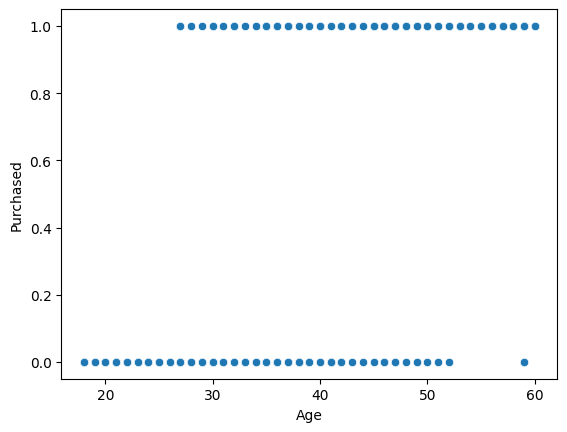

In [ ]:
sns.scatterplot(x="Age",y="Purchased",data=dataset)
plt.show()

In [ ]:
x = dataset[["Age"]]
y = dataset[["Purchased"]]


In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)


In [ ]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(x_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:1408: DataConversionWarning: A column-vector y was passed when a 1d array was expected. Please change the shape of y to (n_samples, ), for example using ravel().
  y = column_or_1d(y, warn=True)


LogisticRegression()

In [ ]:
lr.score(x_test,y_test)*100

91.25

In [ ]:
lr.predict([[40]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

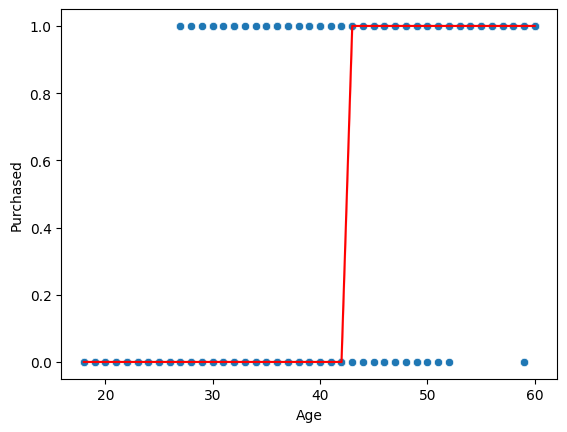

In [ ]:
sns.scatterplot(x="Age",y="Purchased",data=dataset)
sns.lineplot(x="Age",y=lr.predict(x),data=dataset,color="red")
plt.show()

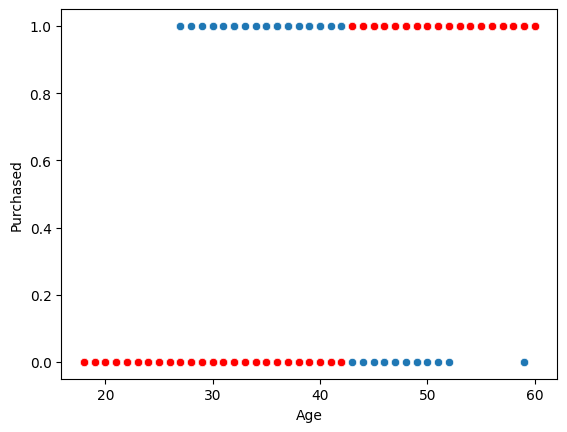

In [ ]:
sns.scatterplot(x="Age",y="Purchased",data=dataset)
sns.scatterplot(x="Age",y=lr.predict(x),data=dataset,color="red")
plt.show()

# Multiple Input

In [ ]:
dataset = pd.read_csv("placement_logistic_regression_dataset.csv")

In [ ]:
dataset.head(3)

,cgpa,score,placed
0,5.2,35,0
1,5.5,40,0
2,5.8,38,0


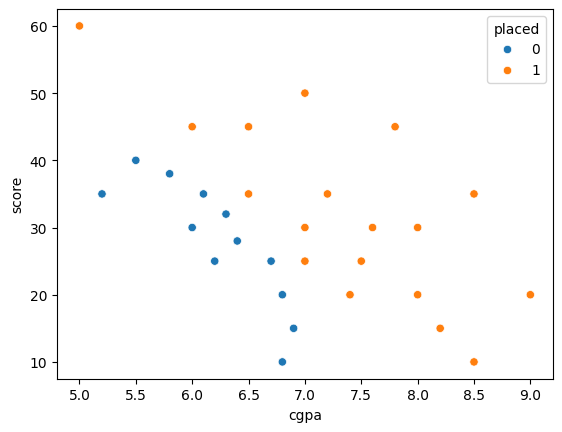

In [ ]:
sns.scatterplot(x="cgpa",y="score",data=dataset,hue="placed")
plt.show()

In [ ]:
x = dataset.iloc[:,:-1]
y = dataset["placed"]

In [ ]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test= train_test_split(x,y,test_size=0.2,random_state=42)

In [ ]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(x_train,y_train)

LogisticRegression()

In [ ]:
lr.score(x_test,y_test)*100

100.0

In [ ]:
lr.predict([[5.2,35]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

In [ ]:
pip install mlxtend

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


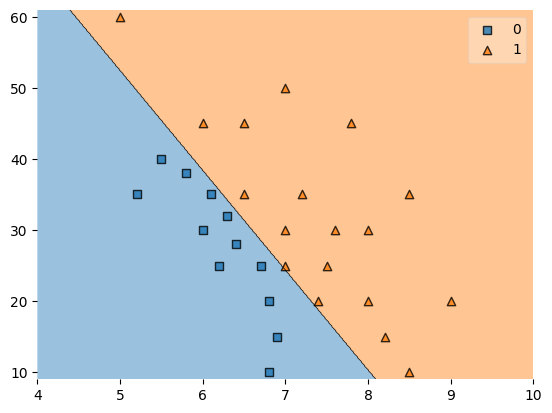

In [ ]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(x.to_numpy(),y.to_numpy(),clf=lr)
plt.show()

In [ ]:
lr.coef_

array([[2.16717105, 0.1542859 ]])

In [ ]:
lr.intercept_

array([-18.9285463])

# Polynomial Input
When data is not linearly separable

Without polynomial features

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
dataset = pd.read_csv("nonlinear_data_circles.csv")

In [2]:
dataset.head(3)

,x1,x2,label
0,0.160594,0.482602,1
1,1.198440,-0.542104,0
2,-0.618907,0.728517,0


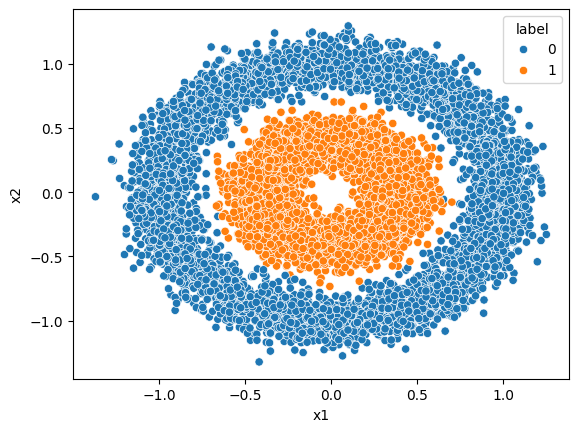

In [3]:
sns.scatterplot(x="x1",y="x2",data=dataset,hue="label")
plt.show()

In [5]:
x = dataset.iloc[:,:-1]
y = dataset["label"]

In [6]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [7]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(x_train,y_train)

LogisticRegression()

In [8]:
lr.score(x_test,y_test)*100

58.5

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


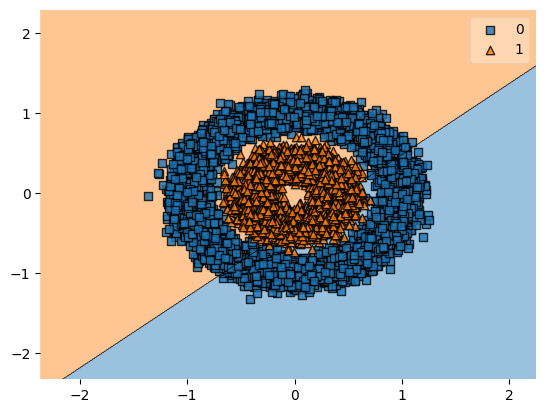

In [9]:
from mlxtend.plotting import plot_decision_regions
plot_decision_regions(x.to_numpy(),y.to_numpy(),clf=lr)
plt.show()

With Polynomial Features

In [10]:
from sklearn.preprocessing import PolynomialFeatures
pf = PolynomialFeatures(degree = 2)
pf.fit(x)

PolynomialFeatures()

In [11]:
x = pd.DataFrame(pf.transform(x))

In [13]:
x

,0,1,2,3,4,5
0,1.0,0.160594,0.482602,0.025790,0.077503,0.232904
1,1.0,1.198440,-0.542104,1.436258,-0.649680,0.293877
2,1.0,-0.618907,0.728517,0.383046,-0.450884,0.530736
3,1.0,1.070839,-0.340617,1.146696,-0.364746,0.116020
4,1.0,0.843196,-0.502865,0.710980,-0.424014,0.252873
...,...,...,...,...,...,...
9995,1.0,0.316968,0.402459,0.100469,0.127566,0.161973
9996,1.0,0.433809,0.188856,0.188191,0.081927,0.035666
9997,1.0,0.285000,0.176336,0.081225,0.050256,0.031094
9998,1.0,0.483035,0.891054,0.233323,0.430410,0.793977


In [14]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [15]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(x_train,y_train)

LogisticRegression()

In [16]:
lr.score(x_test,y_test)*100

99.95

# Multiclass Classification (Logistic Regression)

In [18]:
dataset = pd.read_csv("Iris.csv")

In [19]:
dataset.head(3)

,Id,SepalLengthCm,SepalWidthCm,PetalLengthCm,PetalWidthCm,Species
0,1,5.1,3.5,1.4,0.2,Iris-setosa
1,2,4.9,3.0,1.4,0.2,Iris-setosa
2,3,4.7,3.2,1.3,0.2,Iris-setosa


In [20]:
dataset["Species"].unique()

array(['Iris-setosa', 'Iris-versicolor', 'Iris-virginica'], dtype=object)

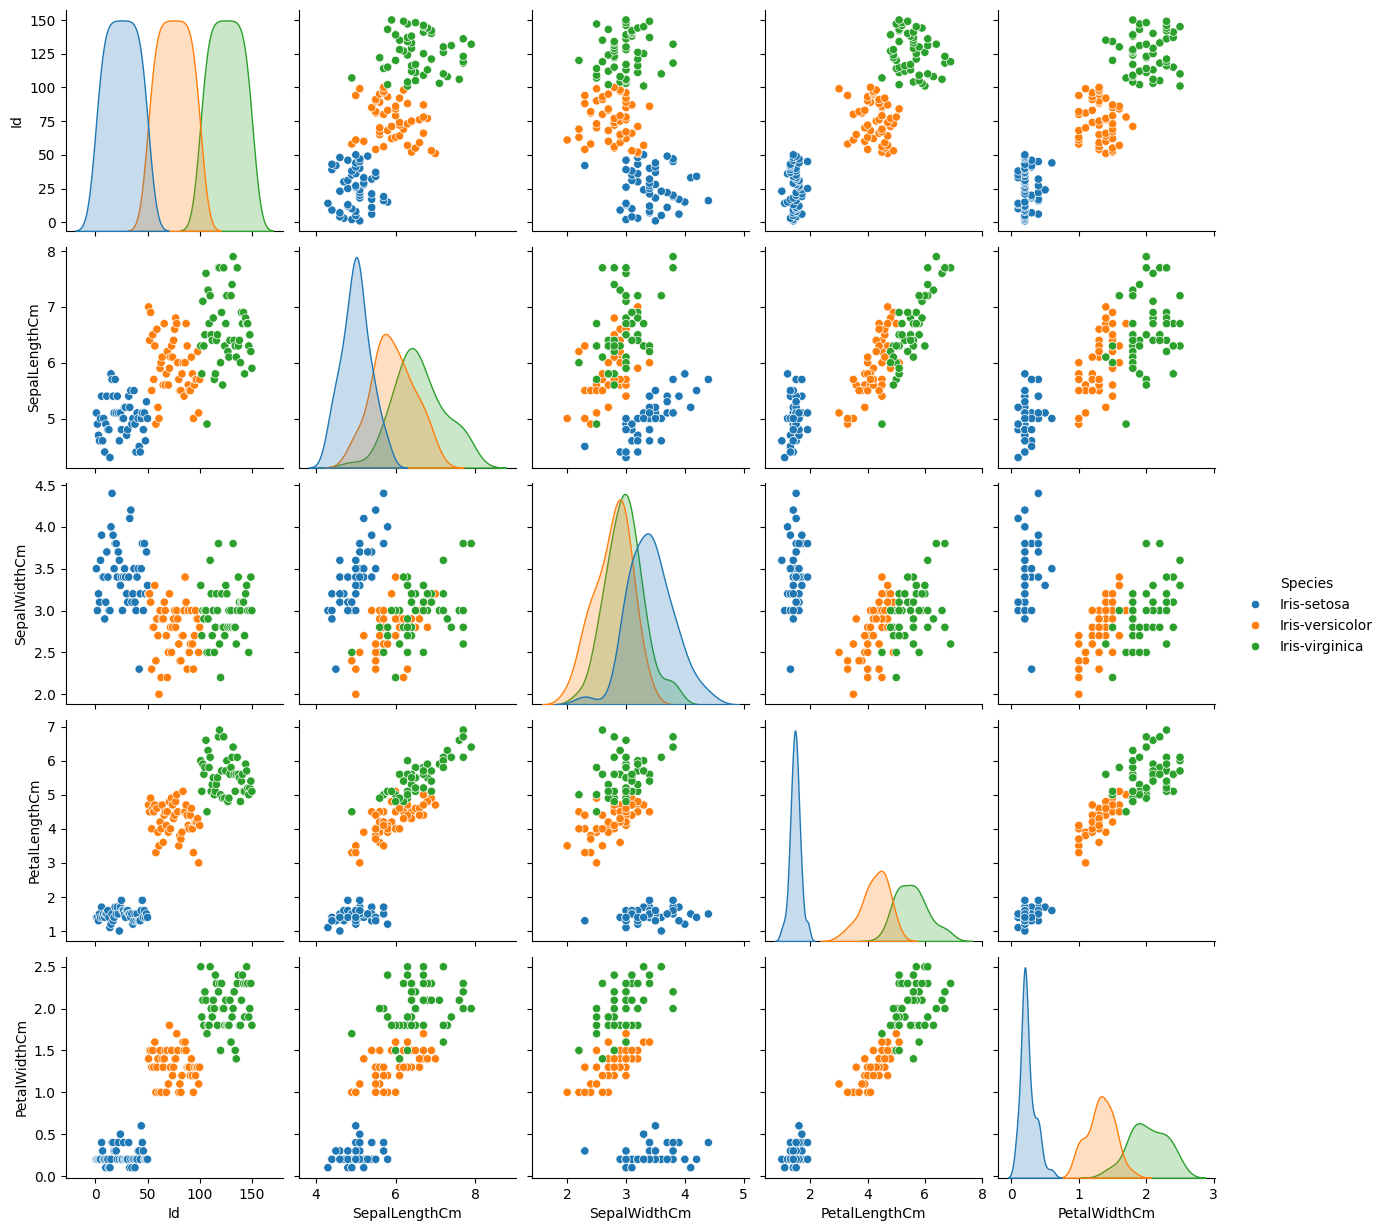

In [21]:
sns.pairplot(data=dataset,hue="Species")
plt.show()

In [23]:
x = dataset.iloc[:,:-1]
y = dataset["Species"]

In [24]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

OVR

In [25]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression(multi_class="ovr")
lr.fit(x_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1256: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. Use OneVsRestClassifier(LogisticRegression(..)) instead. Leave it to its default value to avoid this warning.
  warnings.warn(


LogisticRegression(multi_class='ovr')

In [26]:
lr.score(x_test,y_test)*100

100.0

Multinomial

In [27]:
lr1 = LogisticRegression(multi_class="ovr")
lr1.fit(x_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:1247: FutureWarning: 'multi_class' was deprecated in version 1.5 and will be removed in 1.7. From then on, it will always use 'multinomial'. Leave it to its default value to avoid this warning.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression(multi_class='multinomial')

In [28]:
lr1.score(x_test,y_test)*100

100.0

Auto

In [29]:
lr2 = LogisticRegression()
lr2.fit(x_train,y_train)

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


LogisticRegression()

In [30]:
lr2.score(x_test,y_test)*100

100.0

# Confusion Matrix

In [31]:
dataset = pd.read_csv("placement.csv")

In [32]:
dataset.head(3)

,cgpa,score,placed
0,8.87,75.0,0
1,7.19,79.0,0
2,9.29,45.1,1


In [38]:
x = dataset.iloc[:,:-1]
y = dataset["placed"]

In [39]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [40]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(x_train,y_train)

LogisticRegression()

In [41]:
lr.score(x_test,y_test)*100

66.66666666666666

In [42]:
from sklearn.metrics import confusion_matrix,precision_score,recall_score,f1_score
cf = confusion_matrix(y_test,lr.predict(x_test))

In [43]:
cf

array([[7, 4],
       [4, 9]])

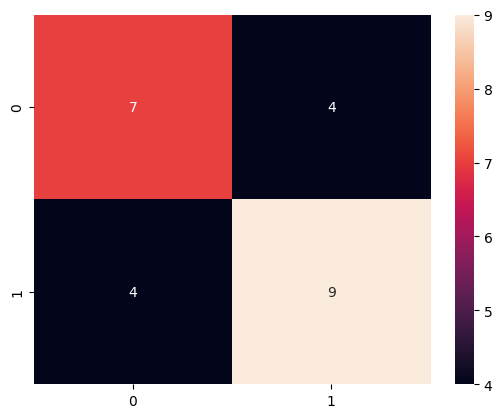

In [44]:
sns.heatmap(cf,annot=True)
plt.show()

In [45]:
precision_score(y_test,lr.predict(x_test))*100

69.23076923076923

In [46]:
recall_score(y_test,lr.predict(x_test))*100

69.23076923076923

In [47]:
f1_score(y_test,lr.predict(x_test))*100

69.23076923076923

# Imbalanced Dataset

In [48]:
dataset = pd.read_csv("Social_Network_Ads.csv")
dataset.head(3)

,Age,EstimatedSalary,Purchased
0,19,19000,0
1,35,20000,0
2,26,43000,0


Check for imbalance dataset

In [49]:
dataset["Purchased"].value_counts()

,count
Purchased,
0,257
1,143


In [50]:
x = dataset.iloc[:,:-1]
y = dataset["Purchased"]

In [51]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(x,y,test_size=0.2,random_state=42)

In [52]:
from sklearn.linear_model import LogisticRegression
lr = LogisticRegression()
lr.fit(x_train,y_train)

LogisticRegression()

In [53]:
lr.score(x_test,y_test)*100

88.75

In [54]:
lr.predict([[19,19000	]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

In [55]:
lr.predict([[45,26000	]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

Balancing the dataset(Imblearn module)

# Under Sampling

In [56]:
from imblearn.under_sampling import RandomUnderSampler
ru = RandomUnderSampler()
ru_x,ru_y = ru.fit_resample(x,y)

In [57]:
ru_y.value_counts() # equal number of value counts

,count
Purchased,
0,143
1,143


In [58]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(ru_x,ru_y,test_size=0.2,random_state=42)

In [59]:
from sklearn.linear_model import LogisticRegression
lr1 = LogisticRegression()
lr1.fit(x_train,y_train)

LogisticRegression()

In [60]:
lr1.score(x_test,y_test)*100

81.03448275862068

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

In [62]:
lr1.predict([[19,19000]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

In [66]:
lr1.predict([[49,28000]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([1])

# Over Sampling

In [67]:
from imblearn.over_sampling import RandomOverSampler
ro = RandomOverSampler()
ro_x,ro_y = ro.fit_resample(x,y)

In [68]:
ro_y.value_counts()

,count
Purchased,
0,257
1,257


In [69]:
from sklearn.model_selection import train_test_split
x_train,x_test,y_train,y_test = train_test_split(ro_x,ro_y,test_size=0.2,random_state=42)

In [70]:
from sklearn.linear_model import LogisticRegression
lr2 = LogisticRegression()
lr2.fit(x_train,y_train)

LogisticRegression()

In [71]:
lr2.score(x_test,y_test)*100

85.43689320388349

In [72]:
lr2.predict([[19,19000]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([0])

In [73]:
lr2.predict([[49,28000]])

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LogisticRegression was fitted with feature names
  warnings.warn(


array([1])